## Trabajo Final SIG
### Romina De León
[romideleon@gmail.com](romideleon@gmail.com)

### Pleito de tinta: retórica, poder y alteridad en las crónicas rioplatenses ante el ojo computacional


Este trabajo será añadido a mi proyecto de Trabajo Final Integrador, que se inscribe en la intersección de la Historia colonial temprana y las Ciencias Sociales Computacionales, además, busca examinar un corpus censal de cuatro crónicas y un poema del Río de la Plata y Paraguay en los siglos XVI y principios del XVII. La propuesta busca desandar el predominio de estudios filológicos e históricos individuales, por una lectura mixta que adopta un diseño secuencial explicativo sustentado con macroanálisis, estadística textual y análisis geoespacial.

A partir de una matriz rectangular, de datos no estructurados o unidades textuales, conformada por párrafos y estrofas, el plan cuantitativo operacionaliza las dimensiones de legitimación imperial, faccionalismo y alteridad indígena. En el plano espacial, se estructura un GeoDataFrame vectorial donde cada registro representa una mención toponímica o hito geográfico extraído de mi corpus. Bajo los principios de la *minimal computing*, se implementa un flujo portable y reproducible en entornos abiertos de Python, proveyendo de una base empírica tanto para evaluar la singularidad retórico-defensiva de los Comentarios de Cabeza de Vaca frente a sus contemporáneos, como para contrastar las espacialidades textuales coloniales con capas hidrográficas y de poblamiento presentado en el corpus.

In [12]:
# Librería a utilizar en el desarrollo del código
# %pip install geopandas pandas shapely requests
from shapely.geometry import box
import geopandas as gpd
import pandas as pd
import os
import zipfile
import requests
import re
import urllib.request
import numpy as np
import io
import matplotlib.pyplot as plt

### Dataset 1: Itinerario georreferenciado y toponimia de crónicas coloniales rioplatenses

* Fuente (URL): Diseño propio consolidado a partir de extracción de toponimias mediante Reconocimiento de Entidades Nombradas (NER), combinando métodos automáticos y curaduría manual, en el marco de las ediciones digitales de *Comentarios*, *Relación de las cosas sucedidas*, *Viaje al Río de la Plata*, *La Argentina Manuscrita* y *Argentina y Conquista del Río de la Plata* (HD LAB de CONICET/[Biblioteca digital](https://hdlab.space/biblioteca-digital/)).
* Formato: Mixto, tabular en CSV y scripts estructurados en JavaScript/JSON. Unificados para el  procesamiento como GeoDataFrame/GeoPackage.
    * *Comentarios* = 'comentarios.csv'
    * *Relación de las cosas sucedidas* = 'perohernandezPlaces.js'
    * *Viaje al Río de la Plata* = 'ulrico.csv'
    * *La Argentina Manuscrita* = 'ruydiazPlaces.js'
    * *Argentina y Conquista del Río de la Plata* = 'centeneraPlaces.js'
* Unidad geográfica: Nodos espaciales del área de la Cuenca del Plata y Litoral, asentamientos poblacionales coloniales o aldeas de pueblos originarios, fuertes, ríos, puertos fluviales y accidentes hidrográficos.
* Geometría: Vectorial de puntos (Point) con coordenadas geográficas decimales en el sistema de referencia geodésico WGS 84 (EPSG:4326).
* Resumen de su contenido: Este dataset integra los topónimos históricos citados en mi corpus con sus correspondiencias toponímica y geográfica, mediante pares de coordenadas decimales. Incluye variables en los documentos con descripción de sucesos de capítulos, o circunstancias particulares relacionadas con la entidad geográfica.

In [ ]:
# Dataset 1:
# Ingesta, unificación y georreferenciación de las 5 crónicas

BASE_URL = "https://raw.githubusercontent.com/rominicky/tif-unab/main/maps/"

def leer(nombre):
    with urllib.request.urlopen(BASE_URL + nombre) as r:
        return r.read().decode("utf-8")

# archivo tipo js busco lugares, lat, lon
PAR = re.compile(r'"([^"]+)"\s*:\s*\[\s*(-?\d+(?:\.\d+)?)\s*,\s*(-?\d+(?:\.\d+)?)\s*\]')

def cargar_js(archivo, obra):
    filas = [(n.strip(), float(a), float(b)) for n, a, b in PAR.findall(leer(archivo))]
    df = pd.DataFrame(filas, columns=["lugar", "lat", "lon"]).drop_duplicates()
    df["orden"] = np.nan                 #archivos js no tienen narraciòn
    df["obra"], df["tipo"] = obra, "toponimos"
    return df

# lectura csv Ulrico Schmidel
u = pd.read_csv(BASE_URL + "ulrico.csv")
u["orden"] = range(len(u))
u = u.rename(columns={"Chapter": "episodio", "Location": "lugar",
                      "Latitude": "lat", "Longitude": "lon"})
u["lugar"] = u["lugar"].fillna(u["episodio"])
u["lat"] = pd.to_numeric(u["lat"], errors="coerce")
u["lon"] = pd.to_numeric(u["lon"], errors="coerce")
u = u.dropna(subset=["lat", "lon"])[["lugar", "lat", "lon", "orden"]]
u["obra"], u["tipo"] = "Schmidel", "itinerario"

# CSV de comentarios, elimino col inneesarias
REG = re.compile(
    r'^([^,\n]+),"(?:.*?)",\s*(-?\d+(?:\.\d+)?)\s*,\s*(-?\d+(?:\.\d+)?)\s*,\d+,',
    re.MULTILINE | re.DOTALL,
)
filas = [(c.strip(), float(a), float(b)) for c, a, b in REG.findall(leer("comentarios.csv"))]
c = pd.DataFrame(filas, columns=["lugar", "lat", "lon"])
c["orden"] = range(len(c))
c["obra"], c["tipo"] = "Cabeza de Vaca", "itinerario"

# uno datasets, filtro lo que no es válido
df = pd.concat([
    u, c,
    cargar_js("centeneraPlaces.js", "Barco Centenera"),
    cargar_js("perohernandezPlaces.js", "Pero Hernandez"),
    cargar_js("ruydiazPlaces.js", "Ruy Diaz de Guzman"),
], ignore_index=True)
df = df[df["lat"].between(-90, 90) & df["lon"].between(-180, 180)]
#genero un geodataframe para utilizarlo en los próximos pasos
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326")
#imprimo cantidad de puntos, y primeros registros
print(len(gdf), "puntos")
print(gdf["obra"].value_counts()) 
print(gdf.head())
gdf.to_file("cronicas.gpkg", driver="GPKG")

485 puntos
obra
Ruy Diaz de Guzman    219
Barco Centenera       163
Schmidel               59
Pero Hernandez         25
Cabeza de Vaca         19
Name: count, dtype: int64
                                               lugar        lat        lon  \
0         Zaha Hadidplein 1, 2030 Antwerpen, Belgium  51.221111   4.399722   
1          11540 Sanlúcar de Barrameda, Cádiz, Spain  36.772577  -6.352969   
2            La Palma, Santa Cruz de Tenerife, Spain  28.713383 -17.905781   
3  Fernando de Noronha, State of Pernambuco, 5399...  15.085263 -23.620464   
4                             Islote Fernando Noroña  -3.844798 -32.426892   

   orden      obra        tipo                    geometry  
0    1.0  Schmidel  itinerario    POINT (4.39972 51.22111)  
1    2.0  Schmidel  itinerario   POINT (-6.35297 36.77258)  
2    3.0  Schmidel  itinerario  POINT (-17.90578 28.71338)  
3    4.0  Schmidel  itinerario  POINT (-23.62046 15.08526)  
4    5.0  Schmidel  itinerario   POINT (-32.42689 -3.8

### Dataset 2: Higrografía

* Fuente (URL): IGN ([WFS](https://wms.ign.gob.ar/geoserver/wfs), capas ign:lineas_de_aguas_continentales_perenne y ign:areas_de_aguas_continentales_BH140) y HydroRIVERS de [HydroSHEDS](https://www.hydrosheds.org/products/hydrorivers).
* Formato: WFS (GeoJSON) para el IGN y shapefile para HydroRIVERS, unificados en GeoPackage.
* Unidad geográfica: registros de corrientes de agua, ríos, arroyos, tramos de corrientes, etc.
* Geometría: vectorial, para cursos perennes y, polígonos, para corrientes anchas. Coordenadas WGS 84 
* Resumen de su contenido:
    * IGN, red de ríos de Argentina, con un recorte en la descarga entre longitud: -70 a -47, y latitud: -40 a -21. Contiene 33042 tramos perennes; 743 polígonos.
    * HYDRORivers, red de ríos en América del Sur, se descarga cuenca del Plata. Contiene el recorte: 38336 tramos en dicho recorte.



In [ ]:
# Dataset 2:
# Desarrolle el codigo para obtenerlo y almacenarlo en una variable

# No considero los puntos geográficos que no sean de América del Sur

# Desde IGN obtengo ríos de Argentina según recorte de zona con latitud y longitud
WFS = "https://wms.ign.gob.ar/geoserver/wfs"
BBOX = (-70, -40, -47, -21)   # recorte lat/long

def descargar_capa(capa, bbox=BBOX):
    url = (
        f"{WFS}?service=WFS&version=1.1.0&request=GetFeature"
        f"&typeName={capa}&outputFormat=application/json"
        f"&srsName=EPSG:4326"
        f"&bbox={bbox[0]},{bbox[1]},{bbox[2]},{bbox[3]},EPSG:4326"
    )
    return gpd.read_file(url)

perenne = descargar_capa("ign:lineas_de_aguas_continentales_perenne")   # líneas
anchos = descargar_capa("ign:areas_de_aguas_continentales_BH140")       # polígonos
print("IGN:", len(perenne), "tramos perennes;", len(anchos), "polígonos")
print(perenne.columns.tolist())

rios_ign = pd.concat([perenne.assign(capa="perenne"), anchos.assign(capa="BH140")],
                     ignore_index=True)
rios_ign["fuente"] = "IGN"

# Desde HydroRIVERS ríos de AmSur según recorte de zona de lat y long
URL_HR = "https://data.hydrosheds.org/file/HydroRIVERS/HydroRIVERS_v10_sa_shp.zip"
ZIP_HR = "HydroRIVERS_v10_sa_shp.zip"
BBOX_CUENCA = (-66, -37, -42, -14) #recorte lat/long

if not os.path.exists(ZIP_HR):
    with requests.get(URL_HR, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(ZIP_HR, "wb") as f:
            for bloque in r.iter_content(1024 * 1024):
                f.write(bloque)

with zipfile.ZipFile(ZIP_HR) as z:
    shp = next(n for n in z.namelist() if n.lower().endswith(".shp"))

# cargo los ríos pero filtro por caudal
rios_hr = gpd.read_file(f"zip://{ZIP_HR}!{shp}", bbox=BBOX_CUENCA)
rios_hr = rios_hr[rios_hr["ORD_STRA"] >= 4].copy()     # límite del caudal apra considerar solo ríos medianos y grandes
rios_hr["fuente"] = "HydroRIVERS"
print("HydroRIVERS:", len(rios_hr), "tramos")

# unifico y genero geoframe
cols = ["fuente", "nam", "ORD_STRA", "DIS_AV_CMS", "geometry"]
rios = pd.concat(
    [d.reindex(columns=cols) for d in (rios_ign, rios_hr)], ignore_index=True
)
rios = gpd.GeoDataFrame(rios, crs="EPSG:4326")
print(rios["fuente"].value_counts())

# guardado considerando capas
perenne.to_file("hidrografia.gpkg", layer="ign_perenne", driver="GPKG")
anchos.to_file("hidrografia.gpkg", layer="ign_BH140", driver="GPKG")
rios_hr.to_file("hidrografia.gpkg", layer="hydrorivers", driver="GPKG")
# referencia
CRS_M = "ESRI:102033"  

# solo considero mi recorte de cuenca y hago join espacial con ríos más cercanos
puntos = gdf.cx[BBOX_CUENCA[0]:BBOX_CUENCA[2], BBOX_CUENCA[1]:BBOX_CUENCA[3]].copy()
print("Puntos dentro del área de la cuenca:", len(puntos), "de", len(gdf))
# busco cercanías a los puntos de mi corpus
cerca = gpd.sjoin_nearest(
    puntos.to_crs(CRS_M),
    rios_hr.to_crs(CRS_M)[["geometry", "ORD_STRA", "DIS_AV_CMS"]],
    how="left",
    distance_col="dist_rio_m",
)
cerca = cerca[~cerca.index.duplicated(keep="first")]   # cada punto representa un río
cerca["dist_rio_km"] = cerca["dist_rio_m"] / 1000

print(cerca.groupby("obra")["dist_rio_km"].agg(["count", "median", "max"]).round(1))
print(cerca.sort_values("dist_rio_km", ascending=False)
           [["obra", "lugar", "dist_rio_km"]].head(10))

IGN: 33042 tramos perennes; 743 polígonos
['id', 'gid', 'entidad', 'objeto', 'fna', 'gna', 'nam', 'sag', 'geometry']
HydroRIVERS: 38336 tramos
fuente
HydroRIVERS    38336
IGN            33785
Name: count, dtype: int64
Puntos dentro del área de la cuenca: 294 de 485
                    count  median   max
obra                                   
Barco Centenera        84    11.5  37.5
Cabeza de Vaca          9     2.1  16.4
Pero Hernandez         13     2.5  16.9
Ruy Diaz de Guzman    140     6.0  39.1
Schmidel               48     3.0  30.4
                   obra                    lugar  dist_rio_km
438  Ruy Diaz de Guzman  corregimiento de Tarija    39.065414
192     Barco Centenera             San Salvador    37.540699
416  Ruy Diaz de Guzman                   Tomina    36.839450
226     Barco Centenera                   Tomina    36.836850
287  Ruy Diaz de Guzman                  Cananea    36.801319
427  Ruy Diaz de Guzman          buena esperanza    35.296012
51             Schmi

### Dataset 3: GeoNames para graficar lugares actuales e históricos


* Fuente (URL): (archivos AR.zip, PY.zip, UY.zip y BR.zip)[https://download.geonames.org/export/dump/].
* Formato: TXT separado por tabulaciones, convertido a GeoPackage
* Unidad geográfica: recorte entre latitudes y longitudes que representan la región analizada
* Geometría: Vectorial de puntos (Point) con coordenadas geográficas decimales en el sistema de referencia geodésico WGS 84 (EPSG:4326).
* Resumen de su contenido: Puntos tienen 'name', 'alternatenames' (variantes en otros idiomas), 'feature_class' y 'feature_code' (tipo de lugar), 'population', 'country_code', 'admin1' y 'admin2' y coordenadas.

33638
country_code  feature_class
AR            P                 5544
              S                    2
BR            P                20346
              S                    3
PY            P                 6651
UY            P                 1089
              S                    3
dtype: int64


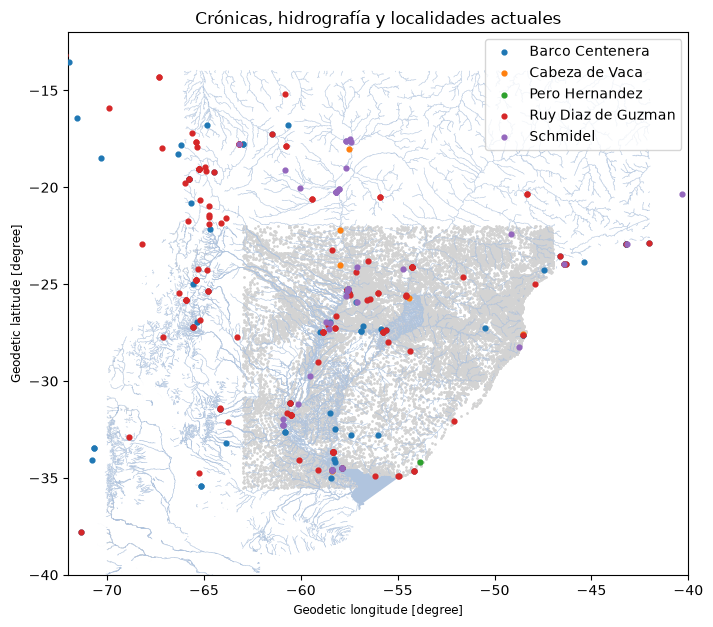

In [ ]:
# Dataset 3:
# Desarrolle el codigo para obtenerlo y almacenarlo en una variable

# No considero lugares fuera de América del Sur

PAISES = ["AR", "PY", "UY", "BR"]
BBOX_GN = (-63, -35.5, -47, -22)    # recorte lon/lat
#columnas a considerar del dataset de geonames
COLUMNAS = [
    "geonameid", "name", "asciiname", "alternatenames", "lat", "lon",
    "feature_class", "feature_code", "country_code", "cc2",
    "admin1", "admin2", "admin3", "admin4",
    "population", "elevation", "dem", "timezone", "modification_date",
]
#descarga de geonames y considero recortes, col y lat/long
def cargar_pais(cc):
    r = requests.get(f"https://download.geonames.org/export/dump/{cc}.zip", timeout=300)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z, z.open(f"{cc}.txt") as f:
        return pd.read_csv(
            f, sep="\t", header=None, names=COLUMNAS, low_memory=False,
            dtype={"admin1": str, "admin2": str, "cc2": str},
            keep_default_na=False, na_values=[""],
        )

#genero df con datos cargados 
df_gn = pd.concat([cargar_pais(cc) for cc in PAISES], ignore_index=True)
#genero un recorte de geonames considerando el bounding box para mi recorte
df_gn = df_gn[df_gn["lon"].between(BBOX_GN[0], BBOX_GN[2])
              & df_gn["lat"].between(BBOX_GN[1], BBOX_GN[3])]

# cargo además poblados y sitios de interés (HSTS, RUIN, ANS) en el geodataframe
es_poblado = df_gn["feature_class"].eq("P")
es_sitio = df_gn["feature_class"].eq("S") & df_gn["feature_code"].isin(["HSTS", "RUIN", "ANS"])
gdf_asent = gpd.GeoDataFrame(
    df_gn[es_poblado | es_sitio].copy(),
    geometry=gpd.points_from_xy(df_gn[es_poblado | es_sitio]["lon"],
                                df_gn[es_poblado | es_sitio]["lat"]),
    crs="EPSG:4326",
)
#muestro registros y agrupaciones por país 
print(len(gdf_asent))
print(gdf_asent.groupby(["country_code", "feature_class"]).size())
gdf_asent.to_file("asentamientos_geonames.gpkg", driver="GPKG")

# gráfico para relevar datos de mi corpus y datasets de referencia
fig, ax = plt.subplots(figsize=(8, 9))
rios.plot(ax=ax, color="lightsteelblue", linewidth=0.4)
gdf_asent.plot(ax=ax, color="lightgray", markersize=1)
gdf.plot(ax=ax, column="obra", legend=True, markersize=12, cmap="tab10", zorder=3)
ax.set_xlim(-72, -40); ax.set_ylim(-40, -12)
ax.set_title("Crónicas, hidrografía y localidades actuales")
plt.show()

### Reflexión final

Desde la lectura distante y con la integración de estos datasets espaciales, en las crónicas, que conforman mi corpus, de la Historia colonial temprana en el sur del Virreinato de Perú, se puede apreciar la superposición de los lugares mencionados con las tierras cercanas a redes acuíferas. En otras palabras, los cauces de agua, en estas narrativas, no solo fueron vías geográficas de ingreso y penetración de territorios, sino el eje vertebral en dichos relatos, y en particular, en tiempo de conquista, colonización e invasión de europeos en este *nuevo mundo*.

En el contexto del **Pleito de tinta**, en el contraste de disputas discursivas y jurídicas, este tipo de análisis puede evidenciar las formas de construcción de legitimidad y su relación a la movilidad específica de cada uno de los protagonistas. En conclusión las herramientas de SIG aplicadas a las Humanidades Digitales pueden abrir otras narrativas, y en este caso en particular, permitir cartografiar el corpus y comprender como dichos pleitos implicaron el control del espacio así como de las rutas hídricas.